In [2]:
import pandas as pd
df = pd.read_csv("ai_resume_screening.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Shape: (30000, 7)
Columns: ['years_experience', 'skills_match_score', 'education_level', 'project_count', 'resume_length', 'github_activity', 'shortlisted']


In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   years_experience    30000 non-null  int64  
 1   skills_match_score  30000 non-null  float64
 2   education_level     30000 non-null  object 
 3   project_count       30000 non-null  int64  
 4   resume_length       30000 non-null  int64  
 5   github_activity     30000 non-null  int64  
 6   shortlisted         30000 non-null  object 
dtypes: float64(1), int64(4), object(2)
memory usage: 1.6+ MB
None


In [4]:
print(df.isnull().sum())

years_experience      0
skills_match_score    0
education_level       0
project_count         0
resume_length         0
github_activity       0
shortlisted           0
dtype: int64


In [5]:
print(df["shortlisted"].value_counts())

shortlisted
Yes    20966
No      9034
Name: count, dtype: int64


In [6]:
print(df["education_level"].value_counts())

education_level
Bachelors      13461
Masters        10524
PhD             3024
High School     2991
Name: count, dtype: int64


In [7]:
X = df.drop("shortlisted", axis=1)
y = df["shortlisted"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.unique())

Features:
['years_experience', 'skills_match_score', 'education_level', 'project_count', 'resume_length', 'github_activity']

Target:
['No' 'Yes']


In [8]:
from sklearn.preprocessing import LabelEncoder

education_encoder = LabelEncoder()
target_encoder = LabelEncoder()

X["education_level"] = education_encoder.fit_transform(X["education_level"])
y = target_encoder.fit_transform(y)

print(X.head())
print("\nTarget values:", y[:10])

   years_experience  skills_match_score  education_level  project_count  \
0                 6                84.7                0              7   
1                 3                59.1                2              5   
2                12               100.0                2             12   
3                14                66.8                1              8   
4                10                99.6                0             10   

   resume_length  github_activity  
0            234              158  
1            502               77  
2            753              381  
3            529              407  
4            754              331  

Target values: [0 0 1 1 1 1 1 0 1 1]


Correlation with Shortlisted:
shortlisted           1.000000
years_experience      0.684845
github_activity       0.646804
project_count         0.599519
resume_length         0.522505
skills_match_score    0.509375
education_level       0.132764
Name: shortlisted, dtype: float64


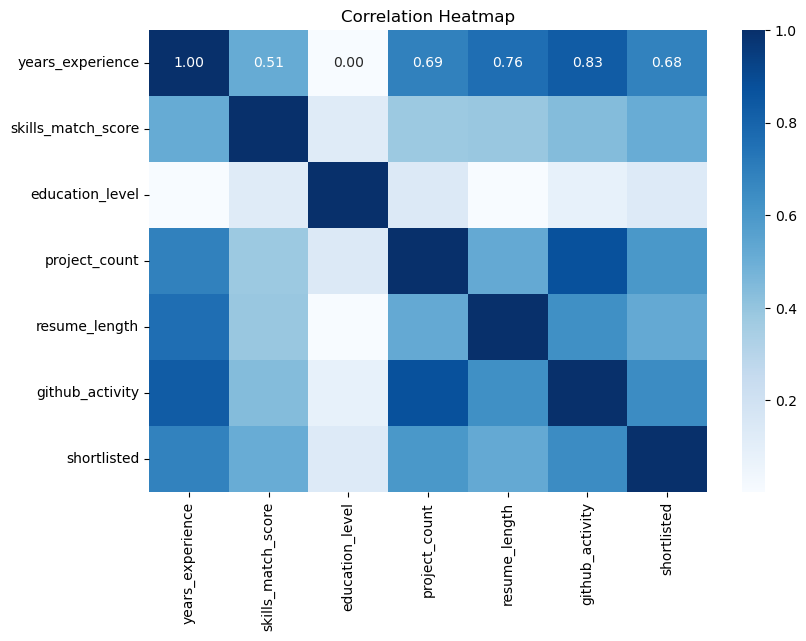

In [9]:
# Correlation Analysis

import matplotlib.pyplot as plt
import seaborn as sns

correlation_data = X.copy()
correlation_data["shortlisted"] = y

corr_matrix = correlation_data.corr()

print("Correlation with Shortlisted:")
print(
    corr_matrix["shortlisted"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Before Scaling:")
print(X_train[:5])

# Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nAfter Scaling:")
print(X_train_scaled[:5])

print("\nFeature Means:")
print(scaler.mean_)

print("\nFeature Standard Deviations:")
print(scaler.scale_)

print("\nTraining data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

print("\nFeature scaling completed successfully!")

Before Scaling:
       years_experience  skills_match_score  education_level  project_count  \
29983                11                91.4                2             21   
19618                10                77.5                2             11   
12656                11                72.2                0             16   
17431                 6                66.7                2              6   
13839                13                83.3                1             10   

       resume_length  github_activity  
29983            716              516  
19618            678              457  
12656            590              434  
17431            306              225  
13839            649              381  

After Scaling:
[[ 0.75294154  1.05443021  0.81863555  2.23129283  0.80163428  1.18925854]
 [ 0.5369411   0.22632553  0.81863555  0.07402138  0.58931992  0.82037495]
 [ 0.75294154 -0.08942662 -1.01276389  1.1526571   0.09764458  0.67657288]
 [-0.32706067 -0.41709394  0

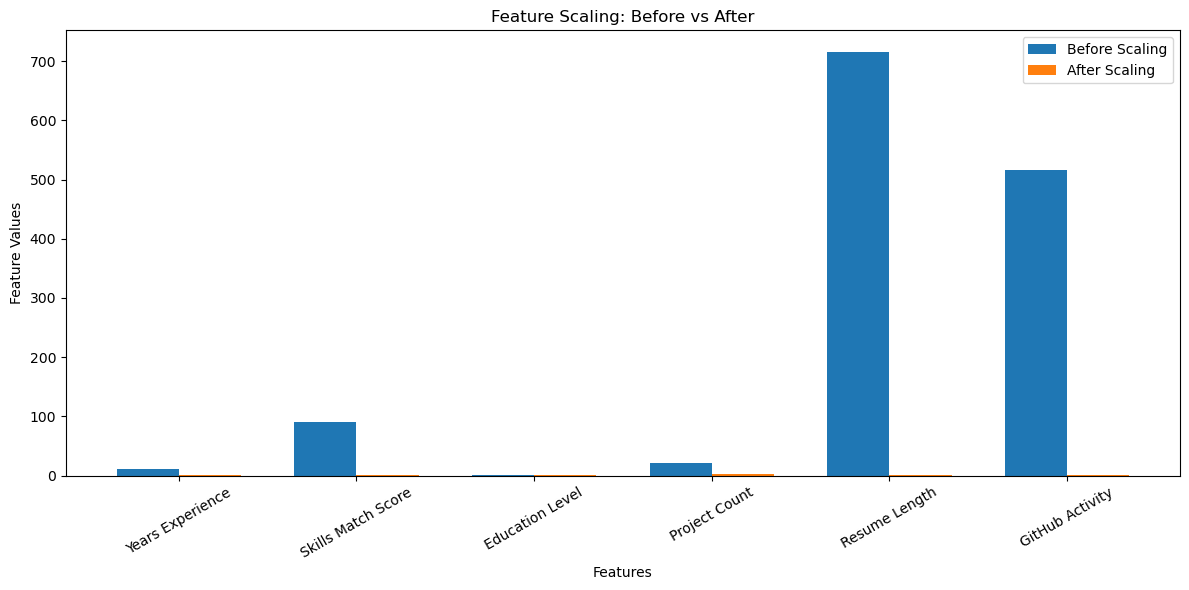

In [12]:
import matplotlib.pyplot as plt
import numpy as np

features = [
    "Years Experience",
    "Skills Match Score",
    "Education Level",
    "Project Count",
    "Resume Length",
    "GitHub Activity"
]

before_scaling = X_train.iloc[0].values
after_scaling = X_train_scaled[0]

x = np.arange(len(features))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    before_scaling,
    width,
    label="Before Scaling"
)

plt.bar(
    x + width/2,
    after_scaling,
    width,
    label="After Scaling"
)

plt.title("Feature Scaling: Before vs After")
plt.xlabel("Features")
plt.ylabel("Feature Values")

plt.xticks(x, features, rotation=30)
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24000, 6)
Testing data: (6000, 6)


In [14]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [15]:
y_pred = model.predict(X_test)

print(y_pred)

[1 0 0 ... 0 1 1]


In [16]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8995

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.82      0.83      1807
           1       0.92      0.94      0.93      4193

    accuracy                           0.90      6000
   macro avg       0.88      0.88      0.88      6000
weighted avg       0.90      0.90      0.90      6000



[[1475  332]
 [ 271 3922]]


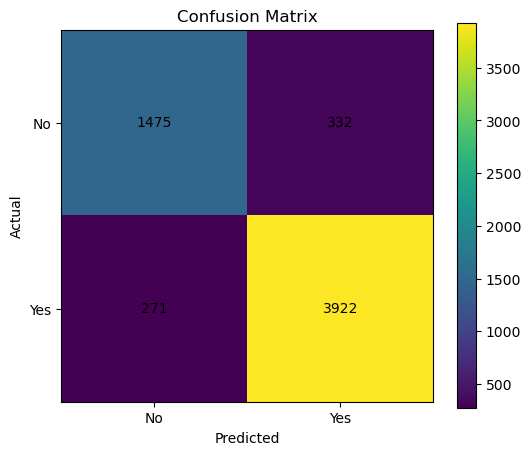

In [17]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xticks([0, 1], ["No", "Yes"])
plt.yticks([0, 1], ["No", "Yes"])

plt.show()

In [18]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [19]:
y_pred_lr = lr_model.predict(X_test)

print(y_pred_lr)

[1 0 0 ... 0 1 1]


In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Accuracy:", accuracy_lr)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Accuracy: 0.9026666666666666

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.83      0.84      1807
           1       0.93      0.93      0.93      4193

    accuracy                           0.90      6000
   macro avg       0.89      0.88      0.88      6000
weighted avg       0.90      0.90      0.90      6000


Confusion Matrix:
[[1500  307]
 [ 277 3916]]


In [22]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Accuracy: 0.862

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.77      0.77      1807
           1       0.90      0.90      0.90      4193

    accuracy                           0.86      6000
   macro avg       0.84      0.84      0.84      6000
weighted avg       0.86      0.86      0.86      6000


Confusion Matrix:
[[1388  419]
 [ 409 3784]]


In [23]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(random_state=42)

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

Accuracy: 0.9058333333333334

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.83      0.84      1807
           1       0.93      0.94      0.93      4193

    accuracy                           0.91      6000
   macro avg       0.89      0.88      0.89      6000
weighted avg       0.91      0.91      0.91      6000


Confusion Matrix:
[[1497  310]
 [ 255 3938]]


In [24]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

gb = GradientBoostingClassifier(random_state=42)

param_grid = {
    "n_estimators": [100, 150],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

grid_search = GridSearchCV(
    gb,
    param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1 Score:")
print(grid_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters:
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 150}

Best CV F1 Score:
0.9360982042709204


In [27]:
best_gb_model = grid_search.best_estimator_

y_pred_tuned = best_gb_model.predict(X_test)

In [28]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Tuned Gradient Boosting Accuracy:")
print(accuracy_score(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Tuned Gradient Boosting Accuracy:
0.9063333333333333

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84      1807
           1       0.93      0.94      0.93      4193

    accuracy                           0.91      6000
   macro avg       0.89      0.88      0.89      6000
weighted avg       0.91      0.91      0.91      6000


Confusion Matrix:
[[1492  315]
 [ 247 3946]]


In [29]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Logistic Regression",
        "Decision Tree",
        "Gradient Boosting",
        "Tuned Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_tuned)
    ],
    "F1 Score": [
        classification_report(y_test, y_pred, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, y_pred_lr, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, y_pred_dt, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, y_pred_gb, output_dict=True)["1"]["f1-score"],
        classification_report(y_test, y_pred_tuned, output_dict=True)["1"]["f1-score"]
    ]
})

comparison

,Model,Accuracy,F1 Score
0,Random Forest,0.899500,0.928614
1,Logistic Regression,0.902667,0.930608
2,Decision Tree,0.862000,0.901382
3,Gradient Boosting,0.905833,0.933065
4,Tuned Gradient Boosting,0.906333,0.933523


In [30]:
import joblib

joblib.dump(best_gb_model, "resume_screening_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [31]:
import os

print(os.path.exists("resume_screening_model.pkl"))

True


In [32]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_gb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

              Feature  Importance
0    years_experience    0.625866
3       project_count    0.132578
5     github_activity    0.106077
1  skills_match_score    0.090918
2     education_level    0.028886
4       resume_length    0.015674


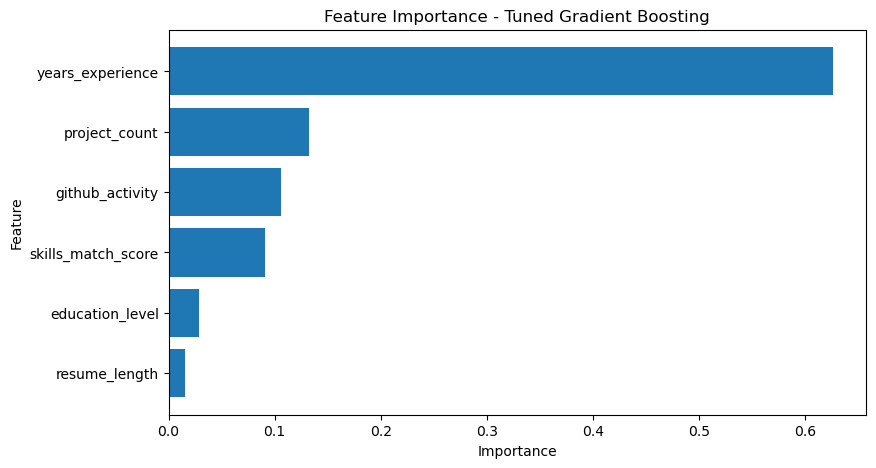

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Tuned Gradient Boosting")

plt.gca().invert_yaxis()

plt.show()